### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_UXVHSPHWWQKI


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
from nptdms import TdmsFile
from scipy import signal
import h5py
import glob, os
import cv2
import seaborn as sns
from roifile import roiread
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
import matplotlib.gridspec as gridspec

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [5]:
import sys
sys.path.append("/home/t/tomoyuki-mano1/projects/OL_calcium")
from calfuncs.io import read_sync_ttl
from calfuncs.drg import compute_osi, compute_dsi, compute_simple_oi, get_ett2, \
                         plot_grating_response, plot_polar_graph, plot_grating_response_combined,\
                         FigParams, compute_qi, compute_qi2, bootstrap_selectivity, bootstrap_selectivity2

### Load data

In [6]:
database = [
    {
        "name": "20250317_rec5",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/20250317_rec5/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec5/ROI_transformed_corrected.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec5/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec8",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/20250318_rec8/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec8/ROI_transformed_corrected.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec8/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250129_rec10",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/20250129_rec10/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250129_squid_cal520/2P/rec10/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250129_squid_cal520/2P/rec10/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250129_rec11",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/20250129_rec11/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250129_squid_cal520/2P/rec11/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250129_squid_cal520/2P/rec11/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    }
]

In [7]:
R, E = [], []
for (k, d) in enumerate(database):
    with pd.HDFStore(d["resp_table"], mode='r') as store:
        r = store["R"]
        e = store["E"]
    r["recording"] = k
    r["cell_id"] = r["neuron"] + k * 1000
    e["recording"] = k
    e = e.reset_index().set_index(["recording", "neuron", "session", "trial", "ori", "sf", "tf", "time"])
    R.append(r)
    E.append(e)
R = pd.concat(R)
R.reset_index(drop=True, inplace=True)
E = pd.concat(E)

In [8]:
# remap angles
mapping = {
    0: 180,
    45: 135,
    90: 90,
    135: 45,
    180: 0,
    225: 315,
    270: 270,
    315: 225
}
R.loc[:, 'ang_osi'] = R['ang_osi'].replace(mapping)
R.loc[:, 'ang_dsi'] = R['ang_dsi'].replace(mapping)
E = E.reset_index()
E.loc[:, "ori"] = E["ori"].replace(mapping)
E = E.reset_index().set_index(["recording", "neuron", "session", "trial", "ori", "sf", "tf", "time"])

In [9]:
display(R)

,neuron,session,qi,osi,resp_osi,ang_osi,pval_osi,flag_osi,dsi,resp_dsi,ang_dsi,pval_dsi,flag_dsi,recording,cell_id
0,0,0,0.074522,0.184572,"[0.042165092468858335, 0.06391145836818966, 0....",45,0.2256,False,0.319157,"[0.042165092468858335, 0.06391145836818966, 0....",225,0.0067,False,0,0
1,0,1,0.051511,0.176859,"[0.0017385612410119877, 0.014237205808559177, ...",135,0.6452,False,0.381143,"[0.0017385612410119877, 0.014237205808559177, ...",135,0.0952,False,0,0
2,0,2,0.067893,0.293709,"[-0.029705470056403695, -0.02579577772423316, ...",45,0.3964,False,0.147745,"[-0.029705470056403695, -0.02579577772423316, ...",225,0.8015,False,0,0
3,1,0,0.046888,0.135708,"[0.019564187258338965, 0.06766875207382156, 0....",135,0.6614,False,0.275874,"[0.019564187258338965, 0.06766875207382156, 0....",135,0.1661,False,0,1
4,1,1,0.052271,0.081288,"[0.008368998422314124, 0.013296273406535395, -...",135,0.9197,False,0.393945,"[0.008368998422314124, 0.013296273406535395, -...",135,0.1052,False,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1468,49,1,0.071655,0.321471,"[-0.037821609534822845, 0.011639364355855086, ...",90,0.2203,False,0.041969,"[-0.037821609534822845, 0.011639364355855086, ...",270,0.9786,False,3,3049
1469,49,2,0.066430,0.036487,"[0.0005906879388295197, 0.012520507324736032, ...",45,0.9818,False,0.116360,"[0.0005906879388295197, 0.012520507324736032, ...",45,0.8370,False,3,3049
1470,50,0,0.059296,0.501931,"[0.017199595438129798, 0.012569259861287005, -...",180,0.0162,False,0.261734,"[0.017199595438129798, 0.012569259861287005, -...",180,0.3563,False,3,3050
1471,50,1,0.072191,0.527824,"[0.008312134000865494, 0.01100007053773875, -0...",0,0.0136,False,0.139388,"[0.008312134000865494, 0.01100007053773875, -0...",0,0.7744,False,3,3050


In [10]:
display(E)

index         y
recording neuron session trial ori sf      tf time                     
0         0      0       0     180 0.00425 3  -2000         0 -0.004644
                                              -1950         1  0.009063
                                              -1900         2 -0.016334
                                              -1850         3 -0.133041
                                              -1800         4 -0.131363
...                                                       ...       ...
3         50     2       17    225 0.00850 3   4250  27574555 -0.039293
                                               4300  27574556  0.081530
                                               4350  27574557 -0.017923
                                               4400  27574558 -0.148594
                                               4450  27574559 -0.202722

[27574560 rows x 2 columns]

### Classify types

In [11]:
# 0 = no response
# 1 = only DoLP
# 2 = only pol light
# 3 = DoLP & pol light
# 4 = only unpol light
# 5 = DoLP & unpol light
# 6 = pol light & unpol light
# 7 = all

for n in R["cell_id"].unique().tolist():
    df = R[(R["cell_id"] == n) & (R["flag_dsi"])]
    p1 =(df["session"] == 0).any()
    p2 =(df["session"] == 1).any()
    p3 =(df["session"] == 2).any()
    R.loc[R["cell_id"] == n, "ds_type"] = 4 * p1 + 2 * p2 + 1 * p3

for n in R["cell_id"].unique().tolist():
    df = R[(R["cell_id"] == n) & (R["flag_osi"])]
    p1 =(df["session"] == 0).any()
    p2 =(df["session"] == 1).any()
    p3 =(df["session"] == 2).any()
    R.loc[R["cell_id"] == n, "os_type"] = 4 * p1 + 2 * p2 + 1 * p3

In [12]:
def show_pie(df, which):
    types = [0, 1, 2, 4, 3, 5, 6, 7]
    labels = ["none", "only DoLP",
              "only pol light", "only unpol light",
              "DoLP & pol light", "DoLP & unpol light",
              "pol light & unpol light", "all"]
    num_elements = []
    total_elements = df["cell_id"].unique().size
    for i in types:
        if which == "ds":
            match = df[df["ds_type"] == i]["cell_id"].unique()
        elif which == "os":
            match = df[df["os_type"] == i]["cell_id"].unique()
        num_elements.append(match.size)
    print("Types:", labels)
    print("# of cells:", num_elements)
    print("Percentage:", [e/total_elements*100 for e in num_elements])
    
    fig, ax = plt.subplots(figsize=(2.,2.), dpi=300)
    
    # Custom autopct function
    def autopct_threshold(pct, threshold=1):
        return f'{pct:.1f}%' if pct >= threshold else ''
    
    wedges, texts, autotexts = ax.pie(
        num_elements, labels=None,
        autopct=lambda pct: autopct_threshold(pct, threshold=1),
        startangle=90, counterclock=False,
        pctdistance=1.1, textprops={'size': 6}
    )
    ax.legend(
        wedges, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.2),  # Adjust vertical position
        ncol=4,  # Two rows for 8 items
        prop={'size': 6}
    )
    ax.axis('equal')
    if which == "ds":
        ax.set_title("DS")
    elif which == "os":
        ax.set_title("OS")
    plt.show()

def show_two_angles(df, which="ds", figsavename=None):
    match = df[df["ds_type"].isin([6,7])]["cell_id"].unique()
    df_filtered = df[df["cell_id"].isin(match)]

    if which == "ds":
        ang0 = df_filtered[df_filtered["session"] == 0]["ang_dsi"]
        ang1 = df_filtered[df_filtered["session"] == 1]["ang_dsi"]
    elif which == "os":
        ang0 = df_filtered[df_filtered["session"] == 0]["ang_osi"]
        ang1 = df_filtered[df_filtered["session"] == 1]["ang_osi"]
    
    # Compute 2D histogram
    if which == "ds":
        angles = np.array([0, 45, 90, 135, 180, 225, 270, 315])
        edges = np.arange(-22.5, 360, 45)  # [-22.5, 22.5, 67.5, ..., 337.5]
    elif which == "os":
        angles = np.array([0, 45, 90, 135, 180])
        edges = np.arange(-22.5, 225, 45)  # [-22.5, 22.5, 67.5, ..., 337.5]
    H, xedges, yedges = np.histogram2d(ang0, ang1, bins=[edges, edges])
    
    fig, ax = plt.subplots(figsize=(2., 2.), dpi=300)
    c = ax.pcolormesh(xedges, yedges, H.T, cmap='viridis', edgecolors='k')
    cax = ax.inset_axes([1.04, 0.2, 0.05, 0.6])
    cbar = fig.colorbar(c, cax=cax, pad=0.04, label="counts")
    
    ax.set_xticks(angles[::2])
    ax.set_yticks(angles[::2])
    if which == "ds":
        ax.set_xlabel('pref. direction 1')
        ax.set_ylabel('pref. direction 2')
    else:
        ax.set_xlabel('pref. orientation 1')
        ax.set_ylabel('pref. orientation 2')
    ax.set_aspect('equal')
    plt.tight_layout()
    if figsavename is not None:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

Types: ['none', 'only DoLP', 'only pol light', 'only unpol light', 'DoLP & pol light', 'DoLP & unpol light', 'pol light & unpol light', 'all']
# of cells: [487, 0, 0, 4, 0, 0, 0, 0]
Percentage: [99.18533604887983, 0.0, 0.0, 0.8146639511201629, 0.0, 0.0, 0.0, 0.0]


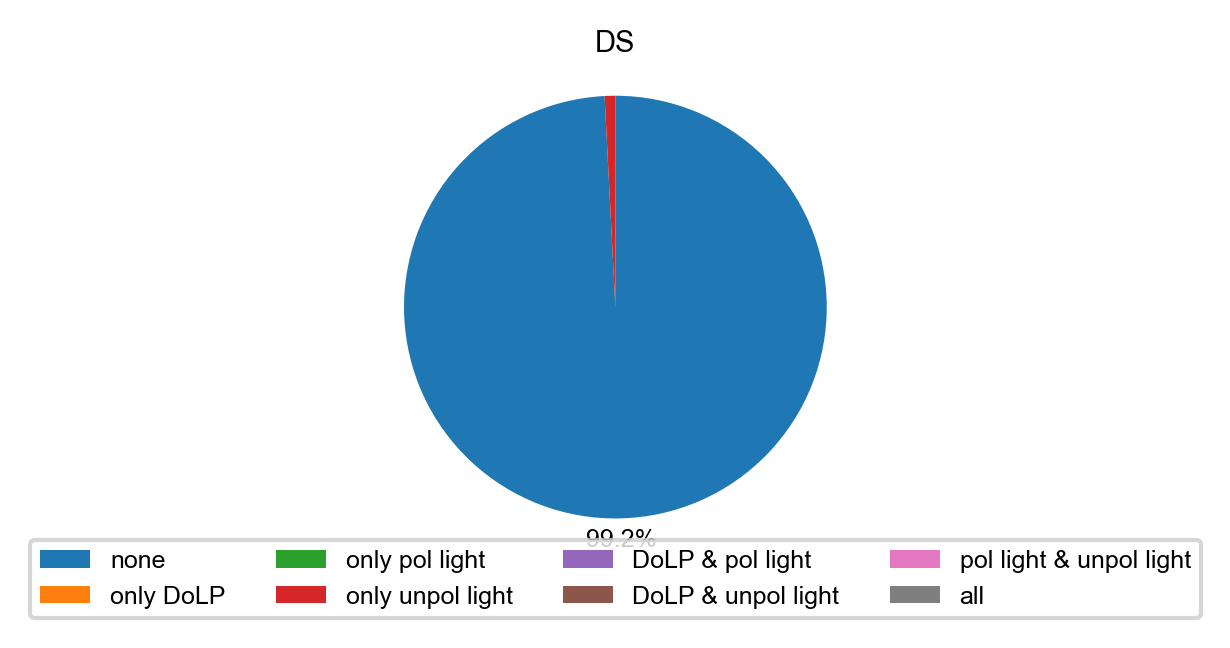

In [13]:
show_pie(R, "ds")

Types: ['none', 'only DoLP', 'only pol light', 'only unpol light', 'DoLP & pol light', 'DoLP & unpol light', 'pol light & unpol light', 'all']
# of cells: [477, 0, 5, 7, 0, 0, 2, 0]
Percentage: [97.14867617107943, 0.0, 1.0183299389002036, 1.4256619144602851, 0.0, 0.0, 0.40733197556008144, 0.0]


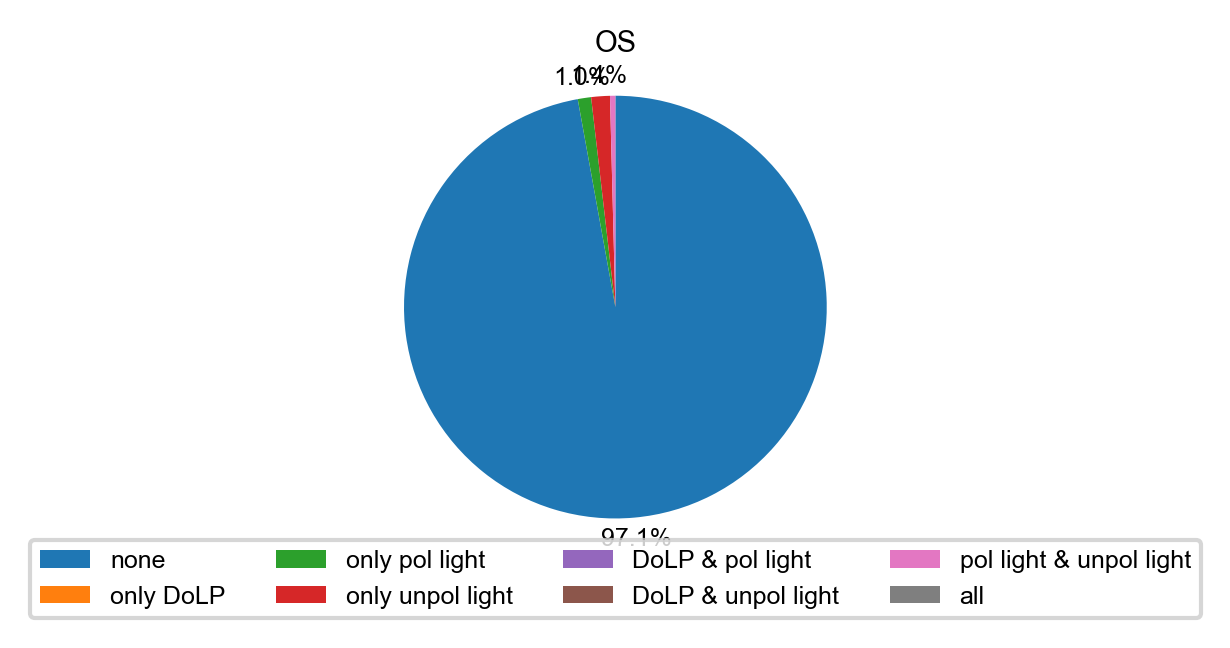

In [14]:
show_pie(R, "os")

### Distribution of DSI & OSI

In [15]:
def plot_distribution(df, which, figsize=(0.8, 1), figsavename=None):

    if which == "ds":
        k1 = "dsi"
        k2 = "ds_type"
    elif which == "os":
        k1 = "osi"
        k2 = "os_type"

    a, b = [], []
    for i in range(8):
        match = df[df[k2] == i]["cell_id"].unique()
        d = df[df["cell_id"].isin(match)]
        if i == 0:
            dsub = d[d["session"].isin([0,1,2])]
        elif i == 1:
            dsub = d[d["session"]==2]
        elif i == 2:
            dsub = d[d["session"]==1]
        elif i == 3:
            dsub = d[d["session"].isin([0,1])]
        elif i == 4:
            dsub = d[d["session"]==0]
        elif i == 5:
            dsub = d[d["session"].isin([0,2])]
        elif i == 6:
            dsub = d[d["session"].isin([1,2])]
        elif i == 7:
            dsub = d[d["session"].isin([0,1,2])]
        v = dsub.groupby("cell_id")[k1].mean().tolist()
        if len(v) > 0:
            a.append(v)
            if i in [1,2,3,4,5,6,7]:
                b.append(v)

    a = np.concatenate(a) if len(a) > 0 else np.array([])
    b = np.concatenate(b) if len(b) > 0 else np.array([])
    print(a.size)
    print(b.size)

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    h1, x1 = np.histogram(a, bins=16, range=[0,0.75])
    h2, x2 = np.histogram(b, bins=16, range=[0,0.75])

    ax.bar(x1[:-1], h1, width=np.diff(x1), align="center", color="gray", alpha=1)
    ax.bar(x2[:-1], h2, width=np.diff(x2), align="center", color="orange", alpha=1)
    if which == "ds":
        ax.set_xlabel("gDSI")
    elif which == "os":
        ax.set_xlabel("gOSI")
    ax.set_ylabel("Num. cells")
    ax.set_xlim(0, 0.75)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    if figsavename is not None:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

def plot_angle_distribution1(df, which):
    if which == "ds":
        k1 = "ang_dsi"
        k2 = "ds_type"
        k3 = "dsi"
    elif which == "os":
        k1 = "ang_osi"
        k2 = "os_type"
        k3 = "osi"

    a = []
    for n in df["cell_id"].unique():
        d = df[df["cell_id"] == n].reset_index()
        i = d.loc[0, k2]
        if i == 0:
            dsub = None
        elif i == 1:
            dsub = d[d["session"]==2]
        elif i == 2:
            dsub = d[d["session"]==1]
        elif i == 3:
            dsub = d[d["session"].isin([0,1])]
        elif i == 4:
            dsub = d[d["session"]==0]
        elif i == 5:
            dsub = d[d["session"].isin([0,2])]
        elif i == 6:
            dsub = d[d["session"].isin([1,2])]
        elif i == 7:
            dsub = d[d["session"].isin([0,1,2])]
        if dsub is not None:
            v = dsub.loc[dsub[k3].idxmax(), k1]
            a.append(v)

    if which == "ds":
        edges = np.arange(-22.5, 360, 45)
    elif which == "os":
        edges = np.arange(-22.5, 180, 45)
    h, bin_edges = np.histogram(a, bins=edges)
    bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

    fig, ax = plt.subplots(figsize=(2,1), dpi=300)
    ax.bar(bin_centers, h, width=40, color="gray", align="center")
    ax.set_xlabel("Angle")
    ax.set_ylabel("Num. cells")
    ax.set_xticks(bin_centers)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    plt.show()

def plot_angle_distribution2(df, which, offset=None, r_max=None, step=5, figsavename=None):
    if which == "ds":
        k1 = "ang_dsi"
        k2 = "ds_type"
        k3 = "dsi"
    elif which == "os":
        k1 = "ang_osi"
        k2 = "os_type"
        k3 = "osi"

    a = []
    for n in df["cell_id"].unique():
        d = df[df["cell_id"] == n].reset_index()
        i = d.loc[0, k2]
        if i == 0:
            dsub = None
        elif i == 1:
            dsub = d[d["session"]==2]
        elif i == 2:
            dsub = d[d["session"]==1]
        elif i == 3:
            dsub = d[d["session"].isin([0,1])]
        elif i == 4:
            dsub = d[d["session"]==0]
        elif i == 5:
            dsub = d[d["session"].isin([0,2])]
        elif i == 6:
            dsub = d[d["session"].isin([1,2])]
        elif i == 7:
            dsub = d[d["session"].isin([0,1,2])]
        if dsub is not None:
            v = dsub.loc[dsub[k3].idxmax(), k1]
            a.append(v)

    if which == "ds":
        edges = np.arange(-22.5, 360, 45)
    elif which == "os":
        edges = np.arange(-22.5, 180, 45)
    h, bin_edges = np.histogram(a, bins=edges)
    bin_centers = (bin_edges[:-1] + bin_edges[1:])/2
    bin_centers_rad = np.deg2rad(bin_centers)
    if offset is None:
        offset = h.max() * 0.25
    if r_max is None:
        r_max = h.max() * 1.1
    if which == "ds":
        step = 5  # radial tick interval
    else:
        step = 10

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(1, 1), dpi=300)
    bars = ax.bar(bin_centers_rad, h, bottom=offset, width=np.deg2rad(40),
                  color='gray', lw=0, align='center', zorder=10)
    theta = np.linspace(0, 2 * np.pi, 500)
    ax.plot(theta, [offset]*len(theta), color='black', linewidth=0.5)

    ax.yaxis.grid(False)
    ax.xaxis.grid(False)
    ax.set_yticklabels([])

    # Draw custom concentric rings starting from offset
    r_ticks = np.arange(offset + step, r_max, step)
    theta = np.linspace(0, 2*np.pi, 500)
    for (k, r) in enumerate(r_ticks):
        ax.plot(theta, [r]*len(theta), color='darkgray', linestyle='--', linewidth=0.5)
        if r_ticks.size > 4:
            if k % 3 == 0:
                ax.text(np.deg2rad(0), r, f"{int(r-offset)}", ha='center', va='bottom', fontsize=6)
        else:
            ax.text(np.deg2rad(0), r, f"{int(r-offset)}", ha='center', va='bottom', fontsize=6)

    if which == "os":
        ax.set_theta_zero_location('E')
        ax.set_theta_direction(-1)
        ax.set_thetamin(0)
        ax.set_thetamax(155)
        ax.set_xticks(np.deg2rad([0, 45, 90, 135]))
    else:
        ax.set_theta_zero_location('E')
        ax.set_theta_direction(-1)
        ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
    ax.tick_params(pad=0)

    if figsavename is not None:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

491
4


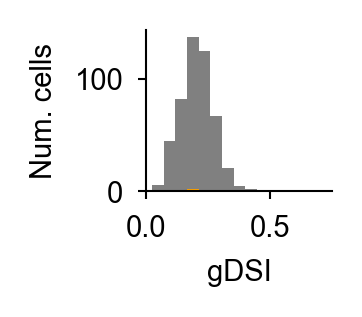

In [16]:
plot_distribution(R, "ds", figsize=(0.8, 0.7), figsavename=os.path.join(tmpdir, "gDSI_distribution.pdf"))

491
14


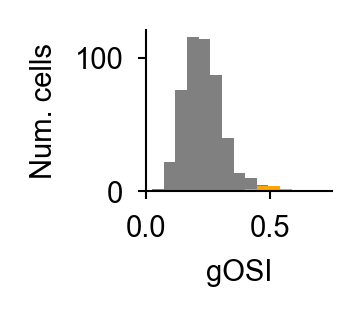

In [17]:
plot_distribution(R, "os", figsize=(0.8, 0.7), figsavename=os.path.join(tmpdir, "gOSI_distribution.pdf"))

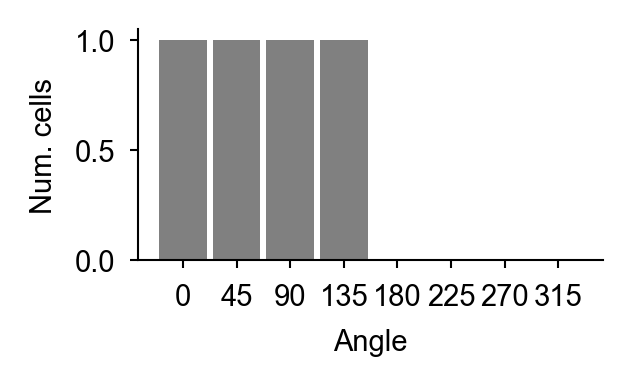

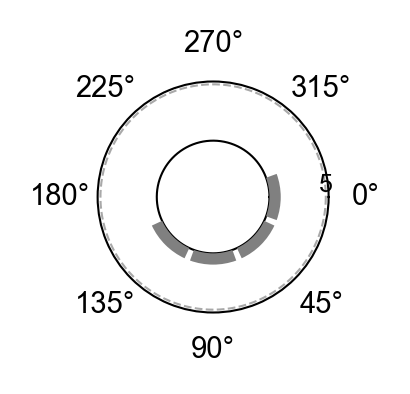

In [18]:
plot_angle_distribution1(R, "ds")
plot_angle_distribution2(R, "ds", offset=5, r_max=11, step=5, figsavename=os.path.join(tmpdir, "DS_angle_distribution.pdf"))

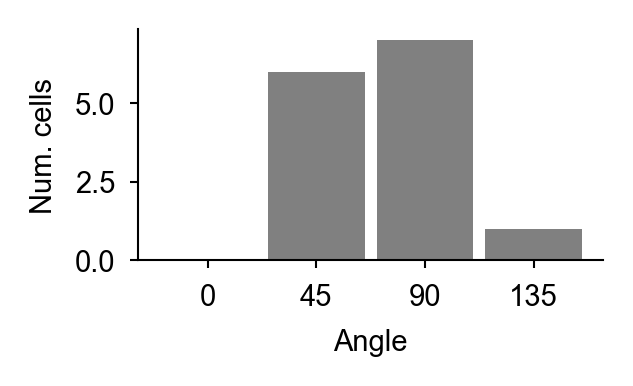

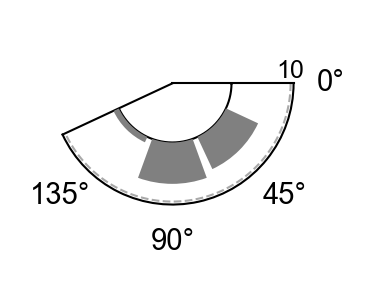

In [19]:
plot_angle_distribution1(R, "os")
plot_angle_distribution2(R, "os", offset=10, r_max=21, step=5, figsavename=os.path.join(tmpdir, "OS_angle_distribution.pdf"))

In [20]:

def plot_grating_response_combined(df, neuron_id, tf, sf, stimulus_train, onset, offset, params: FigParams, ymin1=-0.05, ymax1=0.25, ymin2=-0.05, ymax2=0.25):
    oris = df.index.get_level_values("ori").unique()
    oris = oris.sort_values()
    time = df.index.get_level_values("time").unique() / 1000
    dt = time[1] - time[0]

    fig = plt.figure(figsize=params.size, dpi=params.dpi)
    gs = gridspec.GridSpec(5, len(oris)+2, wspace=0.2,
                           height_ratios=[0.2, 0.1, 1, 1, 1],
                           width_ratios=[1]*9+[1.5])

    # shoow arrows
    for (k, o) in enumerate(oris):
        ax = fig.add_subplot(gs[0, k+1])
        dx, dy = 0.5 * np.cos(np.deg2rad(-o)), 0.5 * np.sin(np.deg2rad(-o))
        ax.arrow(-dx, -dy, 2*dx, 2*dy, head_width=0.4, head_length=0.3, fc='k', ec='k')
        ax.set_xlim([-1.2,1.2])
        ax.set_ylim([-1.2,1.2])
        ax.set_aspect("equal")
        ax.axis("off")

    # show a stimulus train
    for (k, o) in enumerate(oris):
        ax = fig.add_subplot(gs[1, k+1])
        t2 = np.linspace(time[0], time[-1], stimulus_train.size) / 1000
        ax.plot(t2, stimulus_train, color="gray", lw=1)
        ax.axis("off")
        ax.set_xlim([t2[0], t2[-1]])
        ax.set_ylim([-0.25, 1.25])

    # show signals
    df1 = df.xs(neuron_id, level="neuron")
    time_mask = (df1.index.get_level_values("time") >= onset) & (df1.index.get_level_values("time") < offset)
    df2 = df1[time_mask]
    data = []
    for s in range(3):
        responses = []
        for (k, o) in enumerate(oris):
            ax = fig.add_subplot(gs[s+2, k+1])
            df_filtered2 = df2.xs((s, sf, tf, o), level=["session", "sf", "tf", "ori"])
            mat = df_filtered2.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
            R = np.mean(mat, axis=1)
            responses.append(R)
            df_filtered1 = df1.xs((s, sf, tf, o), level=["session", "sf", "tf", "ori"])
            mat1 = df_filtered1.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
            mean = np.nanmean(mat1, axis=0)
            error = np.nanstd(mat1, axis=0)
            mean = ndi.uniform_filter1d(mean, size=4)
            error = ndi.uniform_filter1d(error, size=4)
            ax.plot(time, mean, color="k", linewidth=1, zorder=100)
            # ax.fill_between(time, mean - error, mean + error, color="k", alpha=0.2, linewidth=0, antialiased=True)
            for row in mat1:
                if not np.isnan(row).any():
                    ax.plot(time, ndi.uniform_filter1d(row, size=4), alpha=0.06, color="k", linewidth=0.5)
            ax.set_ylim([ymin1, ymax1])
            ax.set_xlim([time[0], time[-1]])
            ax.axis("off")
            # ax.set_xticks([])
            # ax.set_yticks([])
            # ax.set_xlabel("")
            # ax.set_ylabel("")
            # for sp in ["top", "right", "bottom", "left"]:
            #     ax.spines[sp].set_visible(False)
        responses = np.array(responses)
        data.append({
            "session": s,
            "mean": np.nanmean(responses, axis=1),
            "max": np.nanmax(responses, axis=1),
            "std": np.nanstd(responses, axis=1)
        })

    # show radar
    for s in range(3):
        ax = fig.add_subplot(gs[s+2, 9], polar=True)
        oris_rad = np.radians(oris)
        oris_rad = (-1) * oris_rad
        oris_rad = np.append(oris_rad, oris_rad[0])
        mean = data[s]["mean"]
        mean = np.append(mean, mean[0]) # add the first element to the end to close the loop
        # error = data[s]["std"]
        # error = np.append(error, error[0]) # add the first element to the end to close the loop
        # sem = error / np.sqrt(responses.shape[1])
        # prevent negative
        mean[mean < ymin2] = ymin2
        ax.plot(oris_rad, mean, color="k", linewidth=1, zorder=100)
        # ax.fill_between(oris_rad, mean - sem, mean + sem, color="k", alpha=0.3)
        # ax.set_theta_zero_location("E")  # Set 0 degrees at the right
        # ax.set_theta_direction(-1)  # Clockwise direction
        ax.set_yticklabels([])  # Remove radial ticks
        ax.set_xticklabels([])
        ax.grid(False)
        ax.set_ylim([ymin2, ymax2])
        ax.spines['polar'].set_color('gray')
        # Draw custom concentric rings starting from offset
        r_ticks = np.arange(ymin2 + 0.05, ymax2, 0.05)
        theta = np.linspace(0, 2*np.pi, 360)
        for (k, r) in enumerate(r_ticks):
            ax.plot(theta, [r]*len(theta), color='lightgray', linestyle='--', linewidth=0.5)

    # draw scale bar
    scalebar_axis = fig.add_subplot(gs[2,0])
    scalebar_axis.plot([-1, 0], [ymin1+0.1, ymin1+0.1], color='black', lw=2)
    scalebar_axis.text(-0.5, ymin1+0.1, '1 sec', color='black', ha='left', va='bottom', rotation=0)
    scalebar_axis.plot([-1,-1], [ymin1+0.1, ymin1+0.3], color='k', lw=2)
    scalebar_axis.text(-0.5, ymin1+0.1, '0.2 $\Delta$F/F', color='k', ha='left', va='bottom', rotation=90)
    scalebar_axis.set_xlim(time[0], time[-1])
    scalebar_axis.set_ylim(ymin1, ymax1)
    scalebar_axis.axis("off")

    if params.savename is not None:
        plt.savefig(params.savename, bbox_inches='tight')
    plt.show()


In [21]:
dt = 1e-2
stimulus = np.zeros(int(6.5/dt), dtype=np.float32)
stimulus[0:int(2.0/dt)] = 0
stimulus[int(2.0/dt):int(4.5/dt)] = 1
stimulus[int(4.5/dt):int(6.5/dt)] = 0

In [ ]:
df = R[(R["ds_type"].isin([1,2,3,4,5,6])) & (R["session"] == 0)]
for idx, row in df.iterrows():
    rec = row["recording"]
    nid = row["neuron"]
    d = E.xs(rec, level="recording")
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])
    if rec in [0,1,2,3]:
        plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)
    else:
        print
        plot_grating_response_combined(d, nid, 3, 0.00850, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

In [ ]:
df = R[(R["os_type"].isin([6,7])) & (R["session"] == 0)]
for idx, row in df.iterrows():
    rec = row["recording"]
    nid = row["neuron"]
    d = E.xs(rec, level="recording")
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])
    if rec in [0,1,2,3]:
        plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)
    else:
        print
        plot_grating_response_combined(d, nid, 3, 0.00850, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

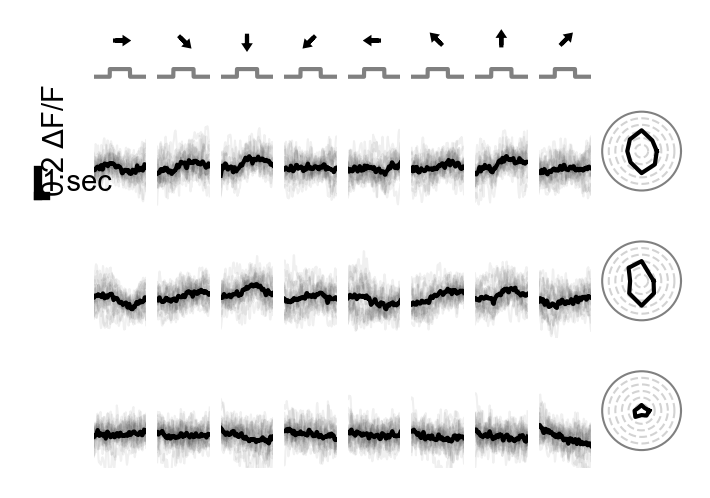

0 19 0 0.41882827642175324 90 0.1019373479859061 0.0001
0 19 0 0.11403499725237295 90 0.1019373479859061 0.5499
0 19 1 0.47004304205101954 90 0.1425860412341765 0.0064
0 19 1 0.2213418721411915 90 0.1425860412341765 0.3862
0 19 2 0.5965961195813256 135 0.08053399641835023 0.4984
0 19 2 0.4484606417234957 135 0.08053399641835023 0.6749


In [28]:
rec = 0
nid = 19
d = E.xs(rec, level="recording")
plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                               params=FigParams(size=[2.8, 1.9], dpi=300, savename=os.path.join(tmpdir, f"{rec}_{nid:03d}.pdf")),
                               ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

d = R[(R["recording"] == rec) & (R["neuron"] == nid)]
for idx, row in d.iterrows():
    print(rec, nid, row["session"], row["osi"], row["ang_osi"], row["qi"], row["pval_osi"])
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])

### Copy data to bucket

In [29]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/plots"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/plots
cp -r /flash/ReiterU/tmp/tomo_UXVHSPHWWQKI/* /bucket/ReiterU/OLdev/analysis/20250410_OGL_DS_OS/plots
